In [16]:
import numpy as np
import matplotlib.pyplot as plt
import math

from matplotlib.patches import Circle

from astro_tools.calculations import rkf45
from astro_tools.data import EARTH, MOON

In [4]:
# abolute tolerances
atol = np.array([
    1e-3,   # Position (m)
    1e-6    # Velocity (m/s)
])

# relative tolerances 
rtol = 1e-8

Generating a rectilinear trajectory out and back from Earth

In [5]:
y0 = np.array([
    6_500_000,          # x position [m]
    7_800              # x velocity [m/s]
])

tspan = (0, 70 * 60)

def derivatives(t: float, f: np.ndarray) -> np.ndarray:
     rates = np.array([
        f[1],
        -EARTH.mu / f[0]**2
     ])
     return rates

t_rectilinear, y_rectilinear = rkf45(y0, tspan, derivatives, rtol, atol)

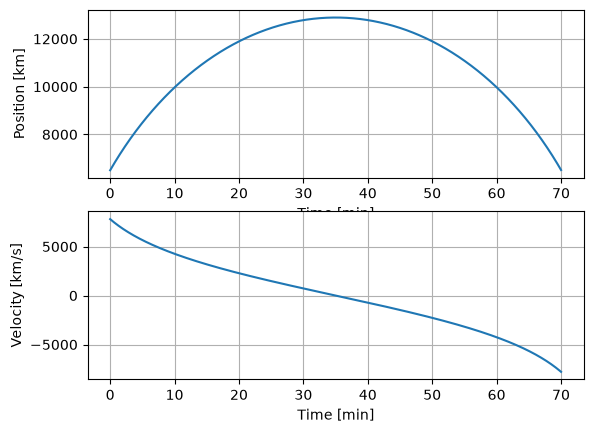

In [6]:
fig, axs = plt.subplots(2, 1)

axs[0].set_xlabel("Time [min]")
axs[0].set_ylabel("Position [km]")
axs[0].plot(t_rectilinear/60, y_rectilinear[:, 0]/ 1000)
axs[0].grid(True)

axs[1].set_xlabel("Time [min]")
axs[1].set_ylabel("Velocity [km/s]")
axs[1].plot(t_rectilinear/60, y_rectilinear[:, 1])
axs[1].grid(True)

Translunar trajectory

In [12]:
deg2rad = math.pi / 180
days = 60 * 60 * 24

r12 = 384_000_000   # meters from Earth to Moon

# given
d0 = 200_000        # meters
phi = -90 * deg2rad
gamma = 20 * deg2rad
v_bo = 10_914.8 # mk/s
tf = 3.16689 * days

# calculate 
M = EARTH.mass + MOON.mass
pi_1 = EARTH.mass / M
pi_2 = MOON.mass / M
mu = EARTH.mu + MOON.mu

W = math.sqrt(mu / r12**3)
x1 = -pi_2 * r12
x2 = pi_1*r12

r0 = d0 + EARTH.radius
x = r0*math.cos(phi) + x1
y = r0*math.sin(phi)

vx = v_bo * (math.sin(gamma)*math.cos(phi) - math.cos(gamma)*math.sin(phi))
vy = v_bo * (math.sin(gamma)*math.sin(phi) + math.cos(gamma)*math.cos(phi))

y0 = np.array([
    x,
    y,
    vx,
    vy
])

def rates(t: float, f: np.ndarray) -> np.ndarray:
    x = f[0]
    y = f[1]
    vx = f[2]
    vy = f[3]

    r1 = np.linalg.norm([x + pi_2*r12, y])
    r2 = np.linalg.norm([x - pi_1*r12, y])

    return np.array([
        vx,
        vy,
        2*W*vy + W**2 * x - EARTH.mu * (x - x1)/r1**3 - MOON.mu*(x - x2) / r2**3,
        -2*W*vx + W**2 * y - (EARTH.mu / r1**3 + MOON.mu / r2**3)*y
    ])

# abolute tolerances
atol = np.array([
    1e-3, 1e-3,     # Position (m)
    1e-6, 1e-6      # Velocity (m/s)
])

# relative tolerances 
rtol = 1e-8

t_translunar, y_translunar = rkf45(y0, (0, tf), rates, rtol, atol)

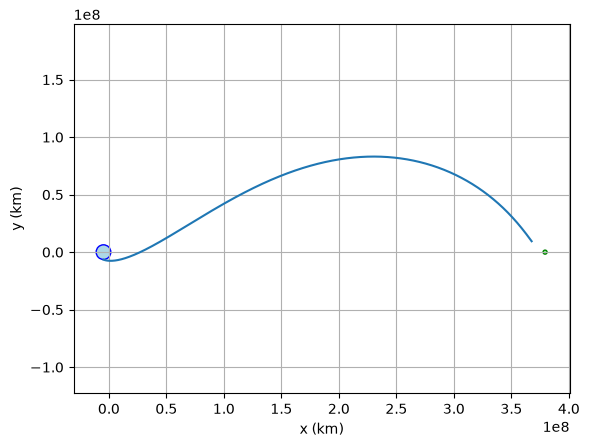

In [23]:
fig, ax = plt.subplots()


ax.axis('equal')
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.grid(True)
ax.plot(y_translunar[:, 0], y_translunar[:, 1])

# add Earth
earth = Circle((x1, 0), EARTH.radius, edgecolor='blue', facecolor='lightblue')
ax.add_patch(earth)

# add Moon
moon = Circle((x2, 0), MOON.radius, edgecolor='green', facecolor='lightgreen')
ax.add_patch(moon)